# Лабораторна робота №2
## Тема: NumPy, pandas і Matplotlib для підготовки, аналізу та візуалізації даних
* **Мета:** Ознайомитися з основами роботи з бібліотеками NumPy, Pandas та Matplotlib для аналізу даних, проведення базових операцій з даними та візуалізації результатів.
* **Студент:** Заболотний Назар
* **Група:** МІТ-31
* **Варіант:** №8 (Вологість: Час, год — Вологість, %)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 8
a = 0.25
b = 48.0
sigma = 1.0

Matplotlib is building the font cache; this may take a moment.


In [2]:
rng = np.random.default_rng(seed)

# 100 рівномірних значень часу від 0 до 20 год
x = np.linspace(0, 20, 100)
y_hat = a * x + b
noise = rng.normal(loc=0, scale=sigma, size=x.size)
y_observed = y_hat + noise

# Об'єднання у матрицю (100x4)
matrix = np.column_stack((x, y_hat, noise, y_observed))
print("Форма (shape):", matrix.shape)
print("Кількість вимірів (ndim):", matrix.ndim)
print("Загальна кількість елементів (size):", matrix.size)
print("Тип даних (dtype):", matrix.dtype)

# Індексація та зріз
print("\nПерший рядок матриці:", matrix[0])
print("Перші 3 значення y_observed (зріз):", matrix[:3, 3])

# Булева фільтрація (значення вологості > 52%)
high_humidity = y_observed[y_observed > 52.0]
print("Кількість спостережень з вологістю > 52%:", high_humidity.size)

# Безпечне оновлення копії фрагмента та видалення елемента
fragment_copy = y_observed[:5].copy()
fragment_copy[0] = 99.9
print("\nОновлена копія перших 5 елементів:", fragment_copy)
print("Оригінальний масив не змінився (перший елемент):", y_observed[0])

y_deleted = np.delete(y_observed, 0)
print("Розмір масиву після видалення 1-го елемента:", y_deleted.size)

# Статистики для y_observed та агрегація по стовпцях (axis=0)
print(f"\ny_observed -> min: {y_observed.min():.2f}, max: {y_observed.max():.2f}, "
      f"mean: {y_observed.mean():.2f}, std: {y_observed.std():.2f}")
print("Середнє по стовпцях матриці (axis=0):", np.round(matrix.mean(axis=0), 4))

Форма (shape): (100, 4)
Кількість вимірів (ndim): 2
Загальна кількість елементів (size): 400
Тип даних (dtype): float64

Перший рядок матриці: [ 0.        48.        -1.7382664 46.2617336]
Перші 3 значення y_observed (зріз): [46.2617336  46.71386226 46.73990339]
Кількість спостережень з вологістю > 52%: 26

Оновлена копія перших 5 елементів: [99.9        46.71386226 46.73990339 47.79989802 45.88943862]
Оригінальний масив не змінився (перший елемент): 46.26173360150312
Розмір масиву після видалення 1-го елемента: 99

y_observed -> min: 45.89, max: 54.43, mean: 50.49, std: 1.90
Середнє по стовпцях матриці (axis=0): [ 1.00000e+01  5.05000e+01 -7.30000e-03  5.04927e+01]


### Пояснення до етапу NumPy
* Отримана структура матриці `shape = (100, 4)` означає двовимірний масив (`ndim = 2`), що містить 100 рядків (спостережень) та 4 стовпці (`x`, `y_hat`, `noise`, `y_observed`), усього 400 елементів.
* Тип даних `dtype = float64` свідчить про те, що всі елементи однорідні та зберігаються як числа з рухомою комою подвійної точності.
* Використання `.copy()` перед модифікацією зрізу дозволило уникнути випадкової зміни вихідного масиву через посилання (`view`).

In [3]:
df = pd.DataFrame({
    "x": x,
    "y_true": y_hat,
    "noise": noise,
    "y_observed": y_observed
})

# Поділ x на три рівні інтервали: low, medium, high
df["group"] = pd.cut(df["x"], bins=3, labels=["low", "medium", "high"])

print("--- Перші 5 рядків (head) ---")
display(df.head())
print("Форма таблиці:", df.shape)
print("\nТипи даних (dtypes):\n", df.dtypes)
print("\nІнформація (info):")
df.info()
print("\nОписова статистика (describe):")
display(df.describe())

# Штучно додаємо 3 пропуски до копії y_observed та 1 дубльований рядок
df_dirty = df.copy()
df_dirty.loc[[5, 25, 70], "y_observed"] = np.nan
df_dirty = pd.concat([df_dirty, df_dirty.iloc[[10]]], ignore_index=True)

print("\nКількість пропусків по стовпцях:\n", df_dirty.isna().sum())
print("Кількість дублікатів:", df_dirty.duplicated().sum())
print("Форма таблиці із засміченнями:", df_dirty.shape)

--- Перші 5 рядків (head) ---


,x,y_true,noise,y_observed,group
0,0.000000,48.000000,-1.738266,46.261734,low
1,0.202020,48.050505,-1.336643,46.713862,low
2,0.404040,48.101010,-1.361107,46.739903,low
3,0.606061,48.151515,-0.351617,47.799898,low
4,0.808081,48.202020,-2.312582,45.889439,low


Форма таблиці: (100, 5)

Типи даних (dtypes):
 x              float64
y_true         float64
noise          float64
y_observed     float64
group         category
dtype: object

Інформація (info):
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   x           100 non-null    float64 
 1   y_true      100 non-null    float64 
 2   noise       100 non-null    float64 
 3   y_observed  100 non-null    float64 
 4   group       100 non-null    category
dtypes: category(1), float64(4)
memory usage: 3.5 KB

Описова статистика (describe):


,x,y_true,noise,y_observed
count,100.000000,100.000000,100.000000,100.000000
mean,10.000000,50.500000,-0.007251,50.492749
std,5.860907,1.465227,1.086997,1.907348
min,0.000000,48.000000,-2.465121,45.889439
25%,5.000000,49.250000,-0.676319,49.234994
50%,10.000000,50.500000,-0.067502,50.830853
75%,15.000000,51.750000,0.689338,52.021324
max,20.000000,53.000000,2.538098,54.433568



Кількість пропусків по стовпцях:
 x             0
y_true        0
noise         0
y_observed    3
group         0
dtype: int64
Кількість дублікатів: 1
Форма таблиці із засміченнями: (101, 5)


In [4]:
# Видалення дубліката
df_clean = df_dirty.drop_duplicates().copy()
print("Форма після видалення дубліката:", df_clean.shape)

# Заповнення пропусків медіаною
median_val = df_clean["y_observed"].median()
df_clean["y_observed"] = df_clean["y_observed"].fillna(median_val)
print("Пропусків після заповнення медіаною:", df_clean.isna().sum().sum())
print("Форма після очищення:", df_clean.shape)

# Демонстрація loc, iloc, булевої фільтрації та сортування
print("\nВибірка через loc (x > 18):")
display(df_clean.loc[df_clean["x"] > 18, ["x", "y_true", "y_observed", "group"]].head())

print("Вибірка через iloc (рядки 0..2, стовпці 0..3):")
display(df_clean.iloc[0:3, 0:4])

print("Топ-3 спостереження за зростанням вологості (сортування):")
display(df_clean.sort_values(by="y_observed", ascending=False).head(3))

# Групування за group (звертаємо увагу на size() vs count())
summary_df = df_clean.groupby("group", observed=False).agg(
    mean_y_observed=("y_observed", "mean"),
    std_y_observed=("y_observed", "std"),
    count_non_null=("y_observed", "count"),
    total_rows=("y_observed", "size")
).reset_index()

print("\nАгрегована таблиця за групами:")
display(summary_df)

Форма після видалення дубліката: (100, 5)
Пропусків після заповнення медіаною: 0
Форма після очищення: (100, 5)

Вибірка через loc (x > 18):


,x,y_true,y_observed,group
90,18.181818,52.545455,52.322685,high
91,18.383838,52.595960,50.973449,high
92,18.585859,52.646465,52.155911,high
93,18.787879,52.696970,52.856849,high
94,18.989899,52.747475,51.496669,high


Вибірка через iloc (рядки 0..2, стовпці 0..3):


,x,y_true,noise,y_observed
0,0.00000,48.000000,-1.738266,46.261734
1,0.20202,48.050505,-1.336643,46.713862
2,0.40404,48.101010,-1.361107,46.739903


Топ-3 спостереження за зростанням вологості (сортування):


,x,y_true,noise,y_observed,group
80,16.161616,52.040404,2.393164,54.433568,high
84,16.969697,52.242424,1.818482,54.060906,high
73,14.747475,51.686869,1.937962,53.624830,high



Агрегована таблиця за групами:


,group,mean_y_observed,std_y_observed,count_non_null,total_rows
0,low,48.832264,1.360863,34,34
1,medium,50.526144,1.354408,33,33
2,high,52.247771,0.990832,33,33


### Пояснення до етапу pandas
* **Вибір медіани для заповнення пропусків:** медіана є стійкою (робастною) до можливих викидів та асиметрії розподілу, на відміну від середнього арифметичного, тому вона не спотворює загальний тренд вологості при відновленні пропущених вимірювань.
* **Різниця між `size()` та `count()`:** метод `count()` підраховує лише непорожні (не-`NaN`) значення у групі для конкретного стовпця, тоді як `size()` повертає загальну кількість рядків у кожній групі незалежно від наявності пропусків.

MAE = 0.8921 %
MSE = 1.2475 %²


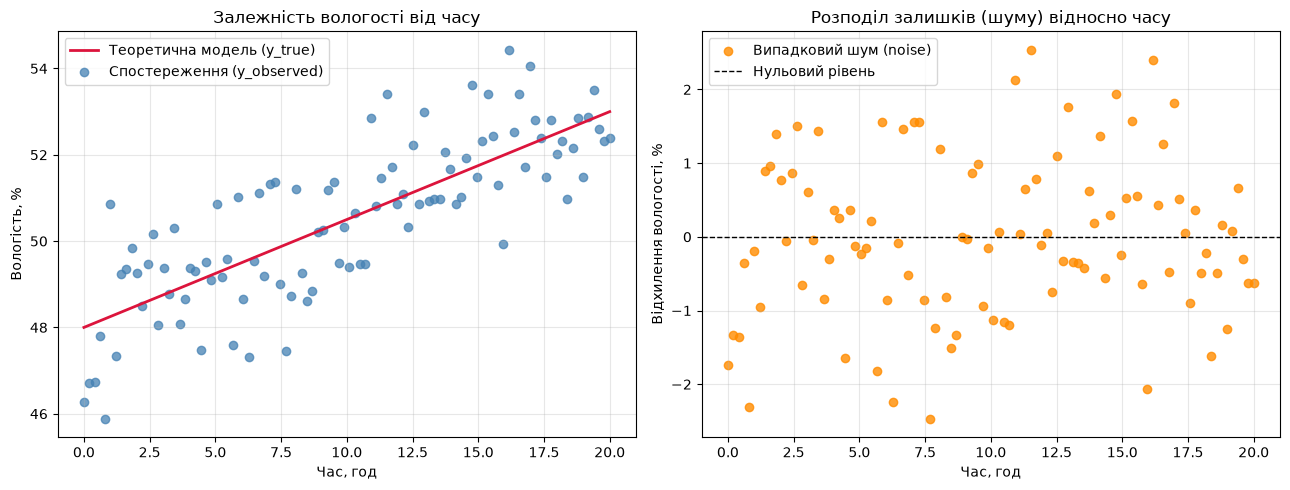

Форма вихідного df_clean: (100, 7)
Форма зчитаного Lab2_results.csv: (100, 7)


In [5]:
# Обчислення MAE та MSE вручну засобами NumPy
mae = np.mean(np.abs(df_clean["y_observed"] - df_clean["y_true"]))
mse = np.mean((df_clean["y_observed"] - df_clean["y_true"]) ** 2)

print(f"MAE = {mae:.4f} %")
print(f"MSE = {mse:.4f} %²")

# Додавання стовпців похибок до DataFrame
df_clean["absolute_error"] = np.abs(df_clean["y_observed"] - df_clean["y_true"])
df_clean["squared_error"] = (df_clean["y_observed"] - df_clean["y_true"]) ** 2

# Побудова Figure з двома Axes (об'єктний інтерфейс)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Графік 1: Лінія y_true разом із точками y_observed
axes[0].plot(df_clean["x"], df_clean["y_true"], color="crimson", linewidth=2, label="Теоретична модель (y_true)")
axes[0].scatter(df_clean["x"], df_clean["y_observed"], color="steelblue", alpha=0.75, label="Спостереження (y_observed)")
axes[0].set_title("Залежність вологості від часу")
axes[0].set_xlabel("Час, год")
axes[0].set_ylabel("Вологість, %")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Графік 2: Діаграма розсіювання залишків noise відносно x
axes[1].scatter(df_clean["x"], df_clean["noise"], color="darkorange", alpha=0.8, label="Випадковий шум (noise)")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="Нульовий рівень")
axes[1].set_title("Розподіл залишків (шуму) відносно часу")
axes[1].set_xlabel("Час, год")
axes[1].set_ylabel("Відхилення вологості, %")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("Lab2_plots.png", dpi=300)
plt.show()

# Збереження результатів
df_clean.to_csv("Lab2_results.csv", index=False)
df_clean.to_parquet("Lab2_results.parquet", index=False)
summary_df.to_csv("Lab2_summary.csv", index=False)

# Перевірка повторного зчитування
df_check = pd.read_csv("Lab2_results.csv")
print("Форма вихідного df_clean:", df_clean.shape)
print("Форма зчитаного Lab2_results.csv:", df_check.shape)

## Висновок
У ході виконання лабораторної роботи №2 було опрацьовано базові інструменти бібліотек NumPy, pandas та Matplotlib на прикладі моделювання зміни вологості повітря протягом 20 годин (варіант №8). Було згенеровано синтетичний набір із 100 спостережень, проведено очищення штучно доданих дублікатів та пропусків із використанням медіани, а також виконано групування даних за часовими інтервалами. Отримані метрики похибки становлять: **MAE = 0.8921  %** (середнє абсолютне відхилення спостережуваної вологості від теоретичної лінійної моделі у відсоткових пунктах) та **MSE = 1.2475 %²** (середній квадрат похибки, який сильніше штрафує великі випадкові викиди шуму). Візуалізація підтвердила лінійне зростання вологості з часом та симетричний розподіл залишків навколо нуля.